In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import random

# Set seeds so Run A and Run B are a 100% fair comparison
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)

# Check if GPU is enabled
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == 'cpu':
    print("WARNING: You are on CPU! Go to Runtime -> Change runtime type -> T4 GPU.")

Using device: cuda


100%|██████████| 170M/170M [00:03<00:00, 54.6MB/s]


Single batch image shape: torch.Size([64, 3, 32, 32])


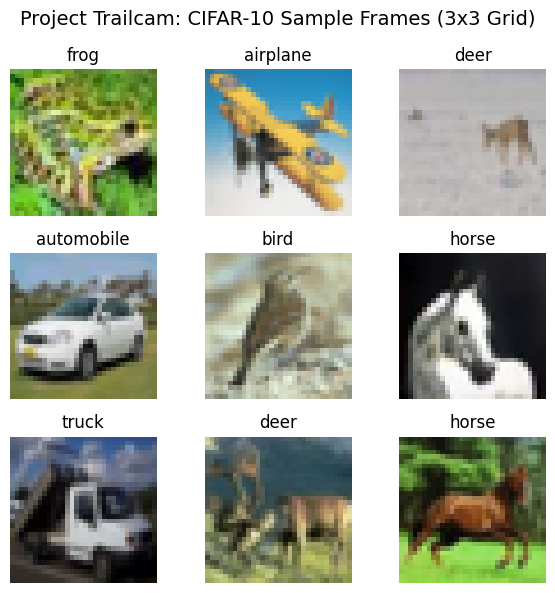

In [8]:
# Use the high-speed byte-identical mirror for CIFAR-10 (downloads in ~3 seconds!)
torchvision.datasets.CIFAR10.url = "https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz"
!rm -rf ./data/cifar-10-python.tar.gz

# CIFAR-10 standard normalization values (RGB channels)
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

# 1. Transforms for Run A (No Augmentation) and Test Data
transform_no_aug = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# 2. Transforms for Run B (With Augmentation - ONLY for training data)
transform_with_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

batch_size = 64

# Download and load datasets
trainset_A = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_no_aug)
trainset_B = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_with_aug)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_no_aug)

trainloader_A = torch.utils.data.DataLoader(trainset_A, batch_size=batch_size, shuffle=True, num_workers=2)
trainloader_B = torch.utils.data.DataLoader(trainset_B, batch_size=batch_size, shuffle=True, num_workers=2)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ('airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# Verify batch shape
images, labels = next(iter(trainloader_A))
print("Single batch image shape:", images.shape) # Should be [64, 3, 32, 32]

# Plot a 3x3 grid of sample images
fig, axes = plt.subplots(3, 3, figsize=(6, 6))
fig.suptitle("Project Trailcam: CIFAR-10 Sample Frames (3x3 Grid)", fontsize=14)
for i, ax in enumerate(axes.flat):
    # Unnormalize image for display
    img = images[i].numpy().transpose((1, 2, 0))
    img = std * img + mean
    img = np.clip(img, 0, 1)
    ax.imshow(img)
    ax.set_title(classes[labels[i].item()])
    ax.axis('off')
plt.tight_layout()
plt.savefig("sample_grid.png", dpi=150)
plt.show()

In [9]:
class TrailcamCNN(nn.Module):
    def __init__(self):
        super(TrailcamCNN, self).__init__()
        # Block 1: 3 input channels (RGB) -> 32 feature maps, then pool to 16x16
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        # Block 2: 32 channels -> 64 feature maps, then pool to 8x8
        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        # Flatten and Fully Connected Layers
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(64 * 8 * 8, 256)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(256, 10) # 10 output classes

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Test wiring with a single batch
test_model = TrailcamCNN().to(device)
sample_out = test_model(images.to(device))
print("Output shape for one batch:", sample_out.shape) # Must be [64, 10]

Output shape for one batch: torch.Size([64, 10])


In [10]:
def train_and_evaluate(model, trainloader, testloader, epochs=10, lr=0.001, run_name="Run"):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    print(f"\n--- Starting {run_name} ---")
    for epoch in range(epochs):
        # Training Phase
        model.train()
        running_loss, correct_train, total_train = 0.0, 0, 0
        for inputs, targets in trainloader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total_train += targets.size(0)
            correct_train += predicted.eq(targets).sum().item()

        train_loss = running_loss / total_train
        train_acc = 100.0 * correct_train / total_train

        # Validation / Test Phase
        model.eval()
        val_loss, correct_val, total_val = 0.0, 0, 0
        with torch.no_grad():
            for inputs, targets in testloader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                total_val += targets.size(0)
                correct_val += predicted.eq(targets).sum().item()

        val_loss = val_loss / total_val
        val_acc = 100.0 * correct_val / total_val

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        print(f"Epoch [{epoch+1:02d}/{epochs:02d}] | "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

    print(f"--> {run_name} Final Test Accuracy: {history['val_acc'][-1]:.2f}%")
    return history

# Run A: Without Augmentation
set_seed(42)
model_A = TrailcamCNN().to(device)
history_A = train_and_evaluate(model_A, trainloader_A, testloader, epochs=10, lr=0.001, run_name="Run A (No Augmentation)")

# Run B: With Augmentation
set_seed(42)
model_B = TrailcamCNN().to(device)
history_B = train_and_evaluate(model_B, trainloader_B, testloader, epochs=10, lr=0.001, run_name="Run B (With Augmentation)")


--- Starting Run A (No Augmentation) ---
Epoch [01/10] | Train Loss: 1.2655, Train Acc: 54.76% | Val Loss: 1.0928, Val Acc: 61.34%
Epoch [02/10] | Train Loss: 0.8869, Train Acc: 68.81% | Val Loss: 0.9159, Val Acc: 67.89%
Epoch [03/10] | Train Loss: 0.7106, Train Acc: 75.03% | Val Loss: 0.8737, Val Acc: 69.25%
Epoch [04/10] | Train Loss: 0.5696, Train Acc: 79.92% | Val Loss: 0.8029, Val Acc: 73.39%
Epoch [05/10] | Train Loss: 0.4373, Train Acc: 84.67% | Val Loss: 0.8691, Val Acc: 72.52%
Epoch [06/10] | Train Loss: 0.3184, Train Acc: 88.75% | Val Loss: 0.9588, Val Acc: 71.59%
Epoch [07/10] | Train Loss: 0.2254, Train Acc: 92.34% | Val Loss: 1.0431, Val Acc: 71.76%
Epoch [08/10] | Train Loss: 0.1562, Train Acc: 94.63% | Val Loss: 1.2224, Val Acc: 71.47%
Epoch [09/10] | Train Loss: 0.1181, Train Acc: 95.86% | Val Loss: 1.3746, Val Acc: 71.56%
Epoch [10/10] | Train Loss: 0.0904, Train Acc: 96.90% | Val Loss: 1.4691, Val Acc: 72.51%
--> Run A (No Augmentation) Final Test Accuracy: 72.51%

-

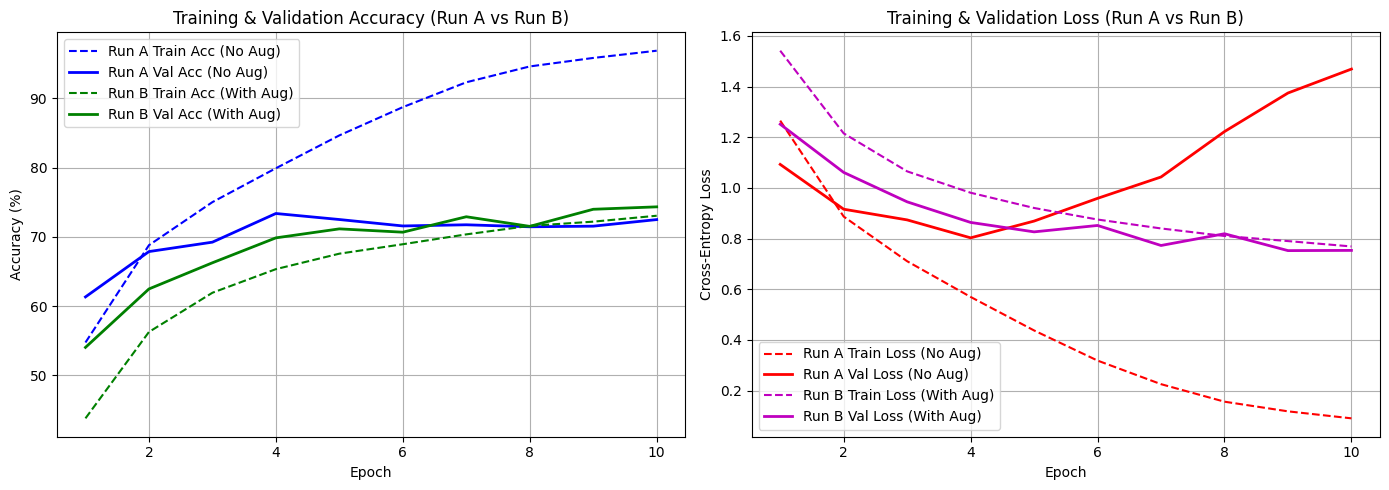

In [11]:
epochs_range = range(1, 11)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Accuracy Comparison
ax1.plot(epochs_range, history_A['train_acc'], 'b--', label='Run A Train Acc (No Aug)')
ax1.plot(epochs_range, history_A['val_acc'], 'b-', linewidth=2, label='Run A Val Acc (No Aug)')
ax1.plot(epochs_range, history_B['train_acc'], 'g--', label='Run B Train Acc (With Aug)')
ax1.plot(epochs_range, history_B['val_acc'], 'g-', linewidth=2, label='Run B Val Acc (With Aug)')
ax1.set_title('Training & Validation Accuracy (Run A vs Run B)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy (%)')
ax1.legend()
ax1.grid(True)

# Plot 2: Loss Comparison
ax2.plot(epochs_range, history_A['train_loss'], 'r--', label='Run A Train Loss (No Aug)')
ax2.plot(epochs_range, history_A['val_loss'], 'r-', linewidth=2, label='Run A Val Loss (No Aug)')
ax2.plot(epochs_range, history_B['train_loss'], 'm--', label='Run B Train Loss (With Aug)')
ax2.plot(epochs_range, history_B['val_loss'], 'm-', linewidth=2, label='Run B Val Loss (With Aug)')
ax2.set_title('Training & Validation Loss (Run A vs Run B)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Cross-Entropy Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

Generating Confusion Matrix for better run: Run B (With Augmentation)


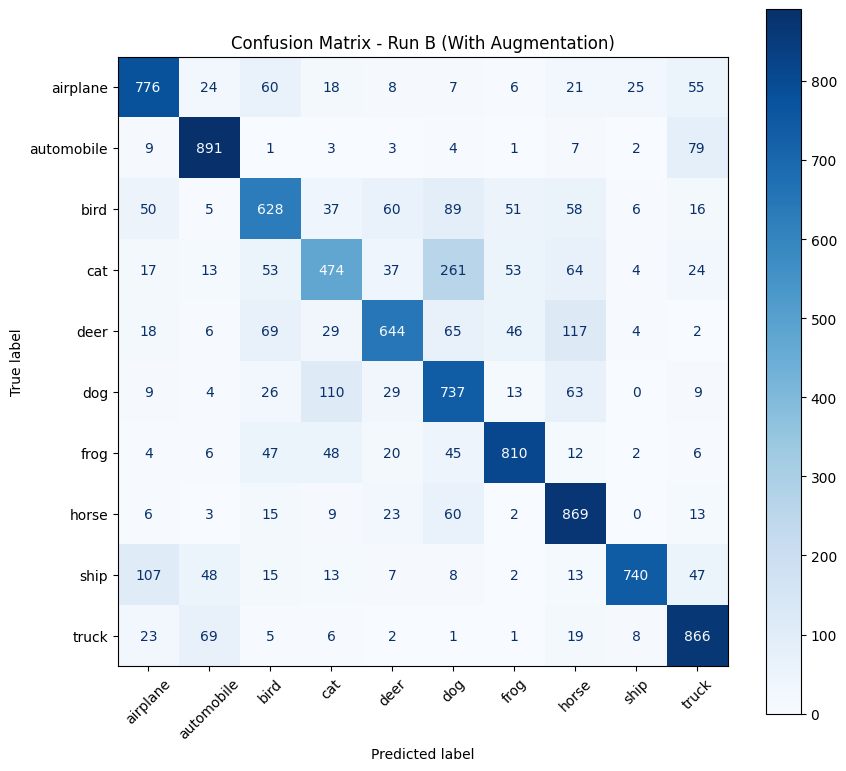


MOST CONFUSED PAIR: True 'cat' predicted as 'dog' (261 times)
Reverse confusion: True 'dog' predicted as 'cat' (110 times)


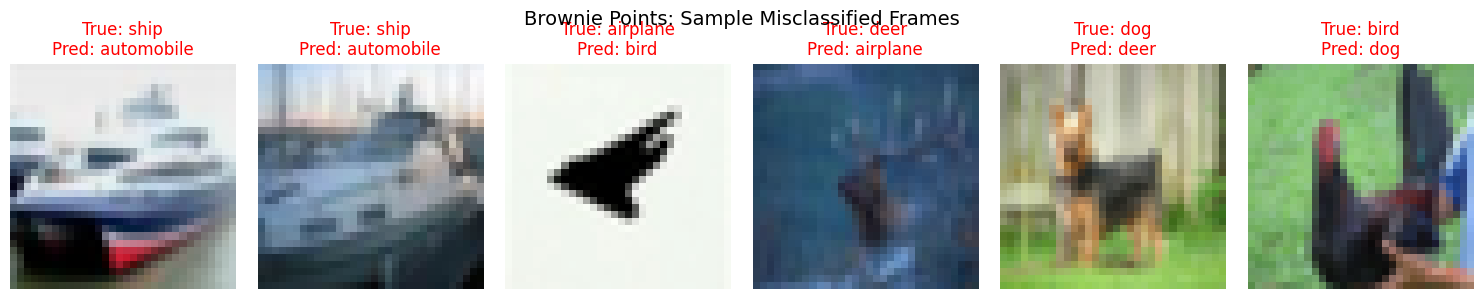

In [12]:
# Pick the better model based on final validation accuracy
if history_B['val_acc'][-1] >= history_A['val_acc'][-1]:
    best_model, best_name = model_B, "Run B (With Augmentation)"
else:
    best_model, best_name = model_A, "Run A (No Augmentation)"

print(f"Generating Confusion Matrix for better run: {best_name}")

all_preds, all_targets = [], []
misclassified_imgs, misclassified_preds, misclassified_true = [], [], []

best_model.eval()
with torch.no_grad():
    for inputs, targets in testloader:
        inputs_dev = inputs.to(device)
        outputs = best_model(inputs_dev)
        _, preds = outputs.max(1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())

        # Collect a few misclassified images for Brownie Points
        if len(misclassified_imgs) < 6:
            wrong_idx = (preds.cpu() != targets).nonzero(as_tuple=True)[0]
            for idx in wrong_idx:
                if len(misclassified_imgs) < 6:
                    misclassified_imgs.append(inputs[idx])
                    misclassified_preds.append(preds.cpu()[idx].item())
                    misclassified_true.append(targets[idx].item())

# 1. Plot Confusion Matrix
cm = confusion_matrix(all_targets, all_preds)
fig, ax = plt.subplots(figsize=(9, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45)
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

# 2. Find which two classes get mixed up the most
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)
max_idx = np.unravel_index(np.argmax(cm_no_diag), cm_no_diag.shape)
print(f"\nMOST CONFUSED PAIR: True '{classes[max_idx[0]]}' predicted as '{classes[max_idx[1]]}' ({cm_no_diag[max_idx]} times)")
print(f"Reverse confusion: True '{classes[max_idx[1]]}' predicted as '{classes[max_idx[0]]}' ({cm_no_diag[max_idx[1], max_idx[0]]} times)")

# 3. Brownie Points: Show failed images
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
fig.suptitle("Brownie Points: Sample Misclassified Frames", fontsize=14)
for i, ax in enumerate(axes.flat):
    img = misclassified_imgs[i].numpy().transpose((1, 2, 0))
    img = std * img + mean
    img = np.clip(img, 0, 1)
    ax.imshow(img)
    ax.set_title(f"True: {classes[misclassified_true[i]]}\nPred: {classes[misclassified_preds[i]]}", color='red')
    ax.axis('off')
plt.tight_layout()
plt.savefig("failed_examples.png", dpi=150)
plt.show()